# 05. Decoding, saved logits and ensembling

**Questions:** Does tuning the decoding help? Which merging rule is best? What should be saved for ensembling, and how well do simple ensembles work?

**Already known from the EDA:** EDA's decoding is fixed argmax, and his fold-model vote scored 0.411 on the leaderboard but has no valid local score.

**Theory to test:** a location is worth predicting when its probability of being correct exceeds about F1/2. On the leaderboard, F1 is low, so a setting tuned on source sentences may be too strict for competition posts. A plain model has a probability threshold for this. A CRF has no probabilities, so the equivalent knob is a **bias** added to the B and I scores before Viterbi decoding.

The settings are tuned on **inner** validation only. The held-out fold just reports the result.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "eda").exists():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "model")]

import pandas as pd
from IPython.display import display

from nerkit import plots
from nerkit.artifacts import combine_models, decode_split, load_logits, majority_vote, row_key, write_submission
from nerkit.config import ARTIFACTS_DIR, SEEDS, WORK_DIR, Config
from nerkit.data import load_test
from nerkit.decisions import base_config
from nerkit.experiment import run_experiment, select_training
from nerkit.metrics import evaluate

NOTEBOOK = "05_decoding_logits_ensembling"
records = [run_experiment("chosen", base_config(seed=seed), NOTEBOOK) for seed in SEEDS]
_, _, inner, heldout = select_training(Config(**records[0]["config"]))
crf = bool(records[0]["config"]["crf"])

chosen: F1 mix 0.875, uk 0.864, ru 0.947, 510 s on cpu


chosen: F1 mix 0.887, uk 0.878, ru 0.947, 608 s on cpu


chosen: F1 mix 0.886, uk 0.876, ru 0.950, 706 s on cpu


## 1. The saved format
Every run saves one file per split in `model/artifacts/<run key>/`: `inner`, `heldout`, `posts`, `labeling` and `test`. Held-out logits from all three folds also give out-of-fold data for the optional logistic-regression stacking.

| Field | Meaning |
| --- | --- |
| `row_ids` | Text ids such as `uk:123` and `test:45` |
| `lengths` | Tokens per text |
| `offsets` | Character start and end per token |
| `logits` | float16 scores per token, in the order O, B, I |
| `meta` | JSON with the config, fold, seed, tag order and, for a CRF, its transition scores |

Windows are already merged, so each text has one row per token. For a CRF, the `logits` are emission scores, not probabilities, and decoding needs `meta["crf"]`. `combine_models` handles both kinds and different tokenizers, projecting them through characters.

In [2]:
key = records[0]["key"]
files = sorted((ARTIFACTS_DIR / key).glob("*"))
display(pd.DataFrame([{"file": path.name, "megabytes": path.stat().st_size / 1e6} for path in files]).round(2))

loaded, meta = load_logits(key, "heldout")
example = next(iter(loaded))
print("Example text:", example)
print("Offsets:", loaded[example][0][:3].tolist())
print("Logits (O, B, I):", loaded[example][1][:3].round(2).tolist())
print("Tags:", meta["tags"], "| fold:", meta["fold"], "| seed:", meta["seed"])

,file,megabytes
0,heldout.npz,2.83
1,inner.npz,0.25
2,labeling.npz,0.01
3,model.pt,0.94
4,posts.npz,0.61
5,test.npz,0.27
6,tokenizer.json,11.95


Example text: ru:4258
Offsets: [[0, 13], [14, 25], [26, 29]]
Logits (O, B, I): [[3.880000114440918, -5.820000171661377, -0.7400000095367432], [1.4700000286102295, -2.549999952316284, -0.8199999928474426], [3.309999942779541, -5.960000038146973, 0.3799999952316284]]
Tags: ['O', 'B', 'I'] | fold: 0 | seed: 3012026


## 2. Threshold, or bias for a CRF
Plain models: a token counts as a location when `1 - P(O)` reaches the threshold. CRF models: a bias is added to the B and I scores before Viterbi decoding.

,bias,precision,recall,f1
0,-1.0,0.930,0.821,0.872
1,-0.5,0.925,0.855,0.889
2,0.0,0.913,0.878,0.895
3,0.5,0.883,0.901,0.892
4,1.0,0.853,0.906,0.879
5,1.5,0.816,0.903,0.857
6,2.0,0.756,0.886,0.816
7,3.0,0.569,0.821,0.672


Best bias on inner validation: 0.0


,precision,recall,f1
default decoding,0.900,0.851,0.875
tuned (bias 0.0),0.900,0.851,0.875
recall-leaning (bias 1.0),0.856,0.877,0.866


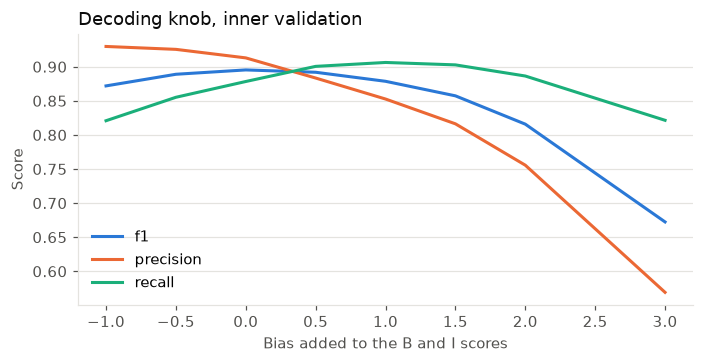

In [3]:
def score(split_logits, rows, crf_scores=None, **options):
    return evaluate(rows, decode_split(split_logits, rows, crf=crf_scores, **options))["mix"]

inner_logits, inner_meta = load_logits(key := records[0]["key"], "inner")
heldout_logits, heldout_meta = load_logits(key, "heldout")
inner_crf, heldout_crf = inner_meta.get("crf"), heldout_meta.get("crf")
if crf:
    knob, GRID, LEAN, label = "bias", [-1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0, 3.0], 1.0, "Bias added to the B and I scores"
else:
    knob, GRID, LEAN, label = "threshold", [round(0.05 * i, 2) for i in range(1, 19)], 0.2, "Threshold on 1 - P(O)"
curve = pd.DataFrame([dict(**{knob: value}, **score(inner_logits, inner, inner_crf, **{knob: value})) for value in GRID])
display(curve.round(3))
plots.threshold_curve(curve, knob, label)
best = float(curve.loc[curve.f1.idxmax(), knob])
tuned = {knob: best}
print(f"Best {knob} on inner validation:", best)
display(pd.DataFrame({
    "default decoding": score(heldout_logits, heldout, heldout_crf),
    f"tuned ({knob} {best})": score(heldout_logits, heldout, heldout_crf, **tuned),
    f"recall-leaning ({knob} {LEAN})": score(heldout_logits, heldout, heldout_crf, **{knob: LEAN}),
}).T.round(3))

## 3. Merging rules and clean-up
- `lenient`: an I without a preceding B starts a location. This is EDA's rule.
- `strict`: an I without a preceding B is dropped.
- `join`: neighboring locations separated only by a hyphen or apostrophe are joined.
- `drop_empty`: removes predictions the metric reduces to nothing, such as `5`.
- `trim_number`: removes a trailing house number such as `, 22`. The metric ignores digits but keeps the comma, so this can change a match.

In [4]:
OPTIONS = {
    "lenient, no clean-up": dict(merge="lenient", drop_empty=False),
    "lenient": dict(merge="lenient"),
    "strict": dict(merge="strict"),
    "join": dict(merge="join"),
    "lenient + trim number": dict(merge="lenient", trim_number=True),
}
display(pd.DataFrame({name: {**{f"inner_{k}": v for k, v in score(inner_logits, inner, inner_crf, **tuned, **options).items()},
                             **{f"heldout_{k}": v for k, v in score(heldout_logits, heldout, heldout_crf, **tuned, **options).items()}}
                      for name, options in OPTIONS.items()}).T.round(4))

,inner_precision,inner_recall,inner_f1,heldout_precision,heldout_recall,heldout_f1
"lenient, no clean-up",0.9130,0.8784,0.8953,0.9000,0.8511,0.8748
lenient,0.9130,0.8784,0.8953,0.9000,0.8510,0.8748
strict,0.9130,0.8784,0.8953,0.9000,0.8510,0.8748
join,0.9027,0.8464,0.8736,0.8898,0.8197,0.8533
lenient + trim number,0.9043,0.8676,0.8856,0.8984,0.8496,0.8733


## 4. Ensembling
All models here trained on the same folds, so the held-out score is valid. This is the correct way to score an ensemble locally, unlike a vote of fold models.

Averaging combines scores, and voting combines final strings. Plain models are averaged as probabilities; CRF models are averaged as log-probabilities with averaged transition scores. The BPE member shows whether a different tokenization adds value.

other_rnn: F1 mix 0.899, uk 0.890, ru 0.959, 788 s on cpu


bpe: F1 mix 0.857, uk 0.849, ru 0.909, 1387 s on cpu


,precision,recall,f1
single seed 3012026,0.900,0.851,0.875
single seed 3012027,0.873,0.901,0.887
single seed 3012028,0.895,0.877,0.886
average of 3 seeds,0.900,0.885,0.893
"vote, at least 1 of 3",0.837,0.920,0.876
"vote, at least 2 of 3",0.902,0.885,0.894
"vote, at least 3 of 3",0.940,0.823,0.878
average of 3 seeds + other RNN,0.904,0.891,0.898
average of 3 seeds + BPE,0.920,0.859,0.889


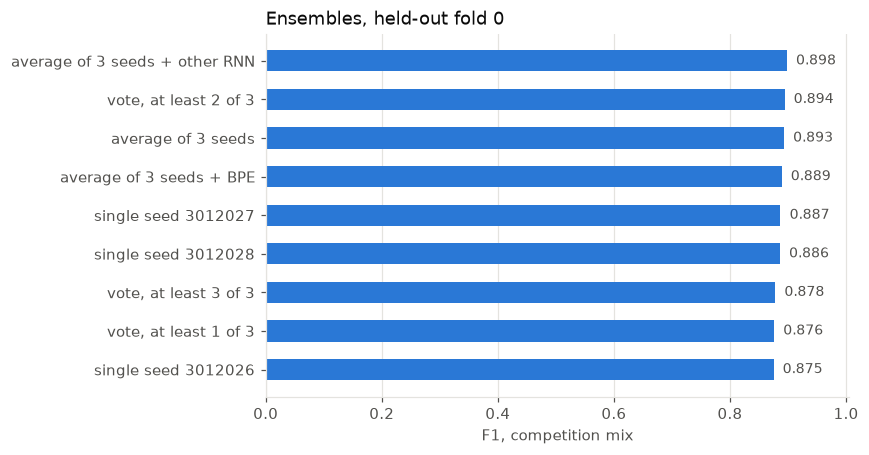

In [5]:
def load_member(record, split):
    return load_logits(record["key"], split)

texts = {row_key(row): row["text"] for row in heldout}
loaded = [load_member(record, "heldout") for record in records]
members, metas = [m for m, _ in loaded], [meta for _, meta in loaded]
results = {}
for record, member, meta in zip(records, members, metas):
    results[f"single seed {record['config']['seed']}"] = score(member, heldout, meta.get("crf"), **tuned)
combined_held, combined_crf = combine_models(members, metas, texts)
results["average of 3 seeds"] = score(combined_held, heldout, combined_crf, **tuned)
predictions = [decode_split(member, heldout, crf=meta.get("crf"), **tuned) for member, meta in zip(members, metas)]
for votes in (1, 2, 3):
    results[f"vote, at least {votes} of 3"] = evaluate(heldout, majority_vote(predictions, votes))["mix"]

other = "gru" if records[0]["config"]["rnn"] == "lstm" else "lstm"
other_record = run_experiment("other_rnn", base_config(rnn=other), NOTEBOOK)
bpe_record = run_experiment("bpe", base_config(tokenizer="bpe", pretrained="none", embedding_mode="random", vocab_size=16_000), NOTEBOOK)
other_member, other_meta = load_member(other_record, "heldout")
bpe_member, bpe_meta = load_member(bpe_record, "heldout")
for label_name, extra_member, extra_meta in (("other RNN", other_member, other_meta), ("BPE", bpe_member, bpe_meta)):
    both, both_crf = combine_models(members + [extra_member], metas + [extra_meta], texts)
    results[f"average of 3 seeds + {label_name}"] = score(both, heldout, both_crf, **tuned)
ensemble_table = pd.DataFrame(results).T.round(3)
display(ensemble_table)
plots.scores_chart(ensemble_table.rename(columns={"f1": "mix_f1"}), "Ensembles, held-out fold 0");

## 5. Test the format, without uploading
This writes two candidates to `model/submissions/`: the tuned setting, and a recall-leaning one. They're fold-0 models for checking the pipeline and the recall theory.

In [6]:
test_rows = load_test()
test_loaded = [load_member(record, "test") for record in records]
test_texts = {row_key(row): row["text"] for row in test_rows}
combined, combined_test_crf = combine_models([m for m, _ in test_loaded], [meta for _, meta in test_loaded], test_texts)
folder = WORK_DIR / "submissions"
for name, options in {"tuned": tuned, "recall_leaning": {knob: LEAN}}.items():
    predictions = decode_split(combined, test_rows, crf=combined_test_crf, **options)
    path = write_submission(folder / f"check_{name}.csv", test_rows, predictions)
    print(f"{path.name}: {sum(map(bool, predictions))} of {len(test_rows)} posts have locations, {sum(map(len, predictions))} locations in total")

check_tuned.csv: 329 of 477 posts have locations, 760 locations in total
check_recall_leaning.csv: 353 of 477 posts have locations, 860 locations in total


## Results summary and decisions

**Setup.** The final configuration (GRU + CRF, frozen aligned vectors, 100k rows per language) was trained with 3 seeds on fold 0. Held-out F1 mix: 0.875, 0.887, 0.886. Logits were saved for every split, and the saved format loads and decodes correctly.

**CRF bias (inner validation F1):** -1.0 → 0.872, -0.5 → 0.889, **0.0 → 0.895**, 0.5 → 0.892, 1.0 → 0.879, 2.0 → 0.816. Precision is above recall at bias 0 (0.913 vs 0.878), but pushing recall with a positive bias does not pay off: the recall-leaning variant (bias 1.0) scored 0.866 vs 0.875 on held-out. Decision: bias 0.

**Merge and clean-up (held-out F1):** lenient 0.875 = strict 0.875 (identical), join 0.853, lenient + trim number 0.873. Dropping strings that the metric normalizes to nothing changes nothing here. Decision: lenient merge, drop empty, no joining, no number trimming.

**Ensembling (held-out F1 mix):** single seeds 0.875 / 0.887 / 0.886; average of 3 seeds **0.893**; votes 1/2/3 of 3: 0.876 / 0.894 / 0.878; average of 3 seeds + an LSTM model 0.898 (the LSTM alone: 0.899); average of 3 seeds + BPE model 0.889 (BPE alone: 0.857). Averaging gains about +0.01 over a single seed and the 2-of-3 vote ties it, so we average logits. An LSTM member helps a little (inside the seed spread, but it adds diversity at no cost); a BPE member does not.

**Local check submissions** (never uploaded): `submissions/check_tuned.csv` (760 locations in 329 of 477 posts) and `check_recall_leaning.csv` (860 locations in 353 posts). Both passed the format check.

**Decisions** (stored in `DECODING` in `nerkit/decisions.py`): lenient merge, drop empty strings, no number trimming, CRF bias 0, and an average of the saved logits of all final models (3+ GRU seeds, optionally one LSTM).